In [91]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import data_utils_all as du
from pathlib import Path

In [92]:
# prepping for later saving (make folder named cleaned inside dataset folder)
# if you want to save it elsewhere, modify OUT_DIR, but DO NOT push your changes! 
# otherwise Ada cries :(

OUT_DIR = Path("../dataset/cleaned")         
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save(df: pd.DataFrame, name: str) -> Path:
    path = OUT_DIR / f"{Path(name).stem}.csv"   # strips any folder or extension passed by mistake
    df.to_csv(path, index=False, mode="x")
    print(f"Saved dataset from {path_in} here: {path}!")

In [93]:
# see the data_utils_all.py file 
# load_clean function loads and does basic cleaning
# all cleaning options can be turned on and off in the function

path_in = "../dataset/sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt"
new_file_name = "Sinetänsalmentie3"
# here you can drop one of the RBCSV values
# if you enter 60 -> 80 gets dropped, and vice versa 
RBCSV = 60


df = du.load_clean(path_in, trim=False, continuous=False, transfix=False)

df.head()

../dataset/sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt: 18128 rows


,Timer(ms),Loc(m),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
0,41518221.1,5004.281,429158.644,7389369.688,10.387099,-0.4559,-15.5989,-0.3722,2.84113,-0.08279,10.00145,0.00626,0.00012,-0.01994,5.04752,1.77365,0.0,0.0,0.0,36.09
1,41518223.6,5004.306,429158.622,7389369.675,9.957436,-0.4534,-15.5984,-0.3753,2.73611,0.04904,10.08783,0.01199,0.00362,-0.02091,5.04737,1.77349,0.0,0.0,0.0,36.09
2,41518226.1,5004.331,429158.600,7389369.663,10.055480,-0.4510,-15.5976,-0.3791,2.72616,-0.06434,10.15394,0.00938,0.00628,-0.02554,5.04805,1.77355,0.0,0.0,0.0,36.09
3,41518228.6,5004.356,429158.579,7389369.650,9.814133,0.0187,-15.4860,-0.5073,2.86240,-0.03215,9.99081,0.00756,-0.01024,-0.01908,5.04947,1.77383,0.0,0.0,0.0,36.09
4,41518231.1,5004.381,429158.557,7389369.637,9.692896,0.0202,-15.4859,-0.5105,3.02184,-0.09944,9.90836,0.00467,0.00091,-0.02129,5.05163,1.77432,0.0,0.0,0.0,36.09


In [94]:
# trimming the ends of the data 
# sensor and timestamps are off and unreliable here, so they need to go
trimmed = du.trim_ends(df)

print("Kept Loc:", round(trimmed["Loc(m)"].min()), "-", round(trimmed["Loc(m)"].max()))
print("Rows:", len(df), "->", len(trimmed))

Kept Loc: 5004 - 5513
Rows: 18128 -> 18128


In [95]:
def fix_transitions(dfcol, threshold=0.05, settle=3, tol=0.02):
    """
    Label a noisy signal with clean whole numbers (baseline 0).
    Rise: whole ramp gets the level it settles on. Drop: labelled 0.
    Stable rows: rounded.

    threshold: row-to-row change that counts as movement
    settle:    still rows needed to count as settled
    tol:       max distance from a whole number to count as on it
    """
    v = dfcol.to_numpy(dtype=float)
    out = np.rint(v).astype(int)                 # default: rounded values
    diff = np.diff(v, prepend=v[0])              # change from previous row
    changed = np.abs(diff) > threshold           # True where the signal moved

    start, direction, quiet = None, 0, 0         # transition start, +1 rise / -1 drop, still rows
    for i in range(len(v)):
        quiet = 0 if changed[i] else quiet + 1

        if changed[i] and start is None:         # a jump begins a transition
            start = i
            direction = 1 if diff[i] > 0 else -1

        # settled: no movement for `settle` rows AND on a whole number
        if start is not None and quiet >= settle and abs(v[i] - round(v[i])) <= tol:
            out[start:i + 1] = round(v[i]) if direction > 0 else 0
            start = None

    if start is not None:                        # data ended mid-transition
        out[start:] = max(round(v[-1]), 0) if direction > 0 else 0

    return pd.Series(out, index=dfcol.index)

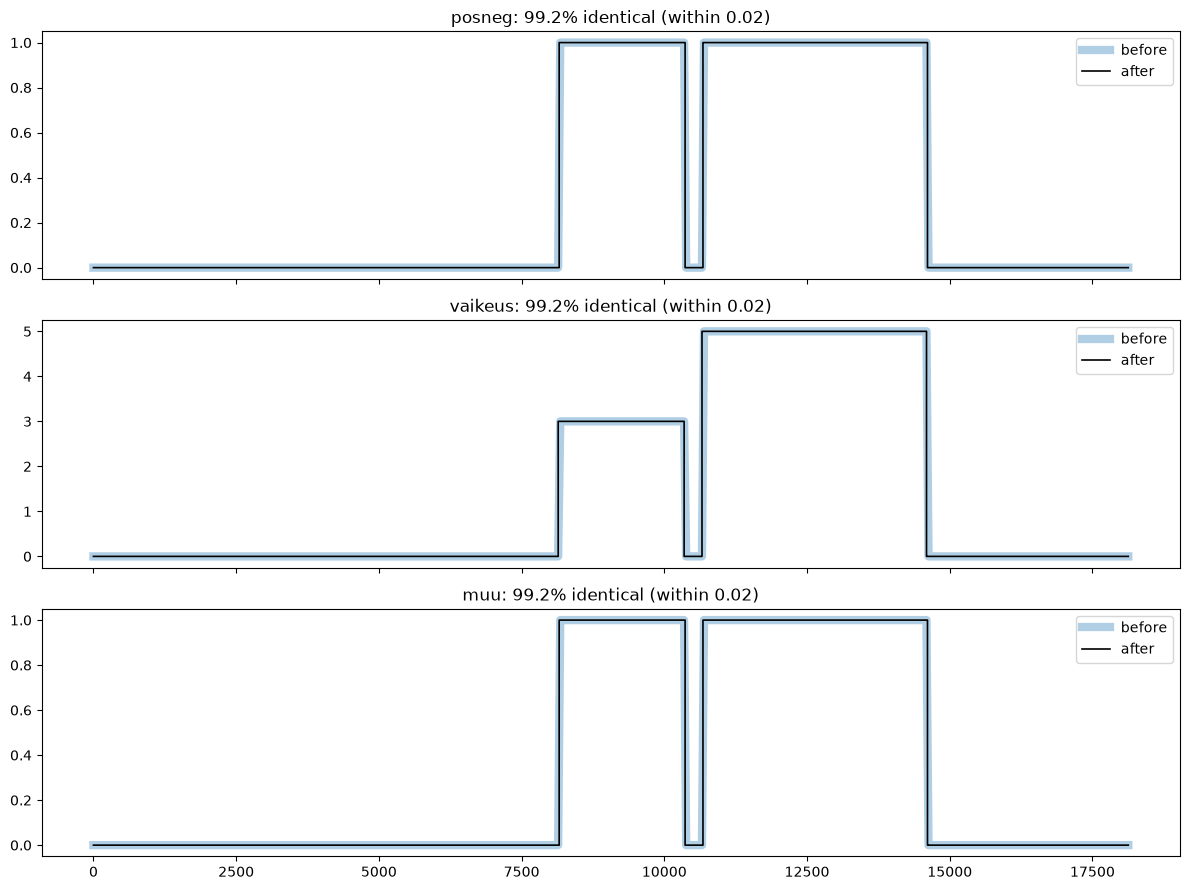

In [96]:
cols_to_fix = ['posneg', 'vaikeus', 'muu']
df_cleaned = df.copy()

for col in cols_to_fix:
    df_cleaned[col] = fix_transitions(df_cleaned[col], threshold=0.05, settle=3, tol=0.02)


def plot_before_after(df_before, df_after, columns, tol=0.02):
    fig, axes = plt.subplots(len(columns), 1, figsize=(12, 3 * len(columns)), sharex=True, squeeze=False)
    for ax, col in zip(axes[:, 0], columns):
        b, a = df_before[col], df_after[col]
        same = (b - a).abs() <= tol

        # before: thick and light underneath, after: thin and dark on top.
        # Where they overlap, the thin line sits inside the thick one.
        ax.plot(b.index, b, color="tab:blue", linewidth=6, alpha=0.35, label="before")
        ax.step(a.index, a, where="post", color="black", linewidth=1.2, label="after")

        # red dots mark rows where they differ by more than tol -> uncomment to see where the function has fixed stuff
        # important that the red dots only show up in up/down slopes -> these are what needs to be changed
        # ax.scatter(b.index[~same], b[~same], color="red", s=18, zorder=3, label="differs")

        ax.set_title(f"{col}: {same.mean():.1%} identical (within {tol})")
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_before_after(df, df_cleaned, cols_to_fix)

In [97]:
# this looks good, applying ficit to the actual dataset
# not really needed for all the columns since some are getting dropped with no use anyway, but may as well 


for col in cols_to_fix:
    df[col] = fix_transitions(df[col], threshold=0.05, settle=3, tol=0.02, )

In [98]:
# creating frostbump column that is just does 0/1
# this makes muu redundant, as well as posneg & vaikeus
 
df["Frostbumps"] = (
    (df["muu"] == 1) |
    (df["muu"] == 2)
).astype(int)

df["Frostbumps"]

0        0
1        0
2        0
3        0
4        0
        ..
18123    0
18124    0
18125    0
18126    0
18127    0
Name: Frostbumps, Length: 18128, dtype: int64

In [99]:
# selecting one of the RBSCV values

if RBCSV == 80:
    df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)"], axis=1)

elif RBCSV == 60:
    df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)", "RBCSV_80(cf)"], axis=1)

else:
    raise ValueError("You left out")


In [100]:
# running saving function created in the beginning
# make sure you change the name for how you want to save it here! 
# the function adds the csv, just put the raw filename here

try:
    save(df, new_file_name)

except FileExistsError:
    print("Dumbdumb, you forgot to define a new name for the saved file :(")


Saved dataset from ../dataset/sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt here: ..\dataset\cleaned\Sinetänsalmentie3.csv!
